In [1]:
#Step 1 rebuild Module 6 Lab 2 Tables

In [2]:
import sqlite3
import pandas as pd

In [3]:
con = sqlite3.connect("world.db")

In [4]:
con.execute("DROP TABLE IF EXISTS City;")

In [5]:
con.execute("""
CREATE TABLE 'City' (
'ID' INTEGER PRIMARY KEY AUTOINCREMENT,
'Name' char(35) NOT NULL default '',
'CountryCode' char(3) NOT NULL default'',
'District' char(20) NOT NULL default'',
'Population' int(11) NOT NULL default '0'
);""")

In [6]:
con.execute("INSERT INTO City VALUES (NULL, 'New York', 'USA', 'New York', 10000000);")
con.execute("INSERT INTO City VALUES (NULL, 'Los Angeles', 'USA', 'California', 4000000);")
con.execute("INSERT INTO City VALUES (NULL, 'Orlando', 'USA', 'Florida', 2700000);")
con.execute("INSERT INTO City VALUES (NULL, 'Dallas', 'USA', 'Texas', 2300000);")
con.execute("INSERT INTO City VALUES (NULL, 'Las Vegas', 'USA', 'Nevada', 1600000);")
con.execute("INSERT INTO City VALUES (NULL, 'Columbus', 'USA', 'Ohio', 1500000);")
con.execute("INSERT INTO City VALUES (NULL, 'Atlanta', 'USA', 'Georgia', 1400000);")
con.execute("INSERT INTO City VALUES (NULL, 'Pittsburgh', 'USA', 'Pennslyvania', 1400000);")
con.execute("INSERT INTO City VALUES (NULL, 'Salt Lake City', 'USA', 'Utah', 1200000);")
con.commit()

In [7]:
df_city = pd.read_sql("SELECT * FROM City", con)
display(df_city)

,ID,Name,CountryCode,District,Population
0,1,New York,USA,New York,10000000
1,2,Los Angeles,USA,California,4000000
2,3,Orlando,USA,Florida,2700000
3,4,Dallas,USA,Texas,2300000
4,5,Las Vegas,USA,Nevada,1600000
5,6,Columbus,USA,Ohio,1500000
6,7,Atlanta,USA,Georgia,1400000
7,8,Pittsburgh,USA,Pennslyvania,1400000
8,9,Salt Lake City,USA,Utah,1200000


In [8]:
# Step 2 Using a WHERE - Population is < 2,300,000

In [9]:
query_where="SELECT Name, Population FROM City WHERE Population < 2300000;"
df_where = pd.read_sql(query_where,con)
display(df_where)

,Name,Population
0,Las Vegas,1600000
1,Columbus,1500000
2,Atlanta,1400000
3,Pittsburgh,1400000
4,Salt Lake City,1200000


In [10]:
# Step 3 Using an ORDER - Alphabetically

In [11]:
query_order="SELECT Name, District FROM City ORDER BY District ASC;"
df_order = pd.read_sql(query_order,con)
display(df_order)

,Name,District
0,Los Angeles,California
1,Orlando,Florida
2,Atlanta,Georgia
3,Las Vegas,Nevada
4,New York,New York
5,Columbus,Ohio
6,Pittsburgh,Pennslyvania
7,Dallas,Texas
8,Salt Lake City,Utah


In [12]:
# Step 4 Using a LIKE - Finding Names with -as- in it

In [13]:
query_like="SELECT Name, District, Population FROM City WHERE Name LIKE '%as%';"
df_like = pd.read_sql(query_like,con)
display(df_like)

,Name,District,Population
0,Dallas,Texas,2300000
1,Las Vegas,Nevada,1600000


In [14]:
# Step 5 Chart of Population

In [15]:
import matplotlib.pyplot as plt

In [16]:
df_chart = pd.read_sql("SELECT Name, Population FROM City ORDER BY Population DESC;", con)

Text(0, 0.5, 'Population (Millions)')

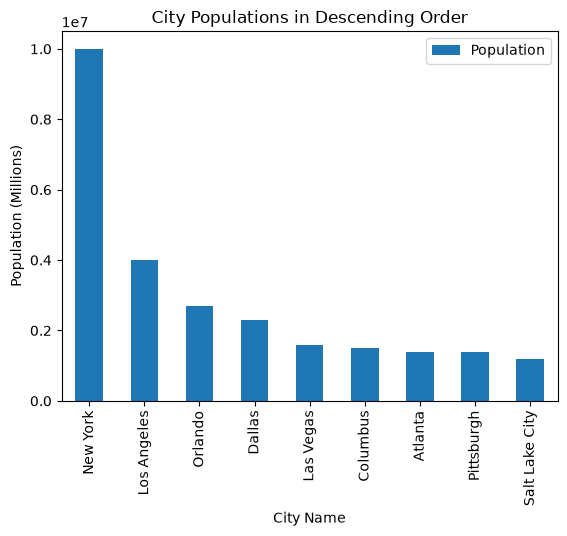

In [17]:
df_chart.plot(
    kind="bar", 
    x="Name", 
    y="Population")

plt.title("City Populations in Descending Order")
plt.xlabel("City Name")
plt.ylabel("Population (Millions)")